# Stage-dependent capacity prediction in doped LNCM cathodes

This notebook loads the deposited dataset, evaluates the four fitted model families
on the original holdout, and redraws the paper's main and supplementary plots
from data, predictions, and saved SHAP values.

In [1]:
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import mean_squared_error, r2_score

data = pd.read_csv("ncm_dataset.csv", index_col="sample_index", float_precision="round_trip")
bundle = joblib.load("ncm_models.joblib")

# Translate manuscript headers to the names stored in the fitted estimators.
aliases = {"x_dopant": "dopant_M", "A_r,dopant": "Mr_dopant", "ΔIR": "△IR", "ΔEN": "△EN"}
X = data.rename(columns=aliases)[list(bundle["features"])]
assert len(data) == 213 and data.index.is_unique

import matplotlib.pyplot as plt
import seaborn as sns
import shap

%matplotlib inline
plt.rcParams.update({"figure.dpi": 100, "font.size": 9})
stages = ("IC", "EC50", "EC100")
style = dict(zip(stages, zip(("#286BA5", "#CB7834", "#8060A9"), ("o", "^", "s"))))
labels = {
    "dopant_M": r"$x_{\mathrm{dopant}}$", "Mr_dopant": r"$A_{r,\mathrm{dopant}}$",
    "△IR": "ΔIR", "△EN": "ΔEN", "L_a": r"$L_a$", "L_c": r"$L_c$",
    "V_min": r"$V_{\min}$", "V_max": r"$V_{\max}$",
}
capacity = r"mAh g$^{-1}$"

## Model performance

Mean CV R² gives each of the five validation folds equal weight.
Pooled OOF R² uses all 170 validation predictions together.
Test RMSE is in mAh g⁻¹.

In [2]:
rows = []
for (model, stage), fitted in bundle["models"].items():
    saved = bundle["predictions"][model, stage].set_index("sample_index")
    held_out = saved.query("dataset == 'Independent_test'")
    assert len(held_out) == 43
    np.testing.assert_allclose(held_out.actual, data.loc[held_out.index, stage], rtol=0, atol=1e-10)
    predicted = fitted.predict(X.loc[held_out.index])
    np.testing.assert_allclose(predicted, held_out.predicted, rtol=0, atol=1e-7)

    oof = saved.query("dataset == 'CV_validation'")
    fold_r2 = [r2_score(fold.actual, fold.predicted) for _, fold in oof.groupby("fold")]
    rows.append((model, stage, np.mean(fold_r2), r2_score(oof.actual, oof.predicted),
                 r2_score(held_out.actual, predicted),
                 mean_squared_error(held_out.actual, predicted) ** 0.5))

metrics = pd.DataFrame(rows, columns=["Model", "Stage", "Mean CV R²", "Pooled OOF R²",
                                     "Test R²", "Test RMSE"])
display(metrics.round(4))

,Model,Stage,Mean CV R²,Pooled OOF R²,Test R²,Test RMSE
0,GBR,IC,0.7410,0.7350,0.7596,17.7992
1,GBR,EC50,0.6974,0.6935,0.7816,15.6035
2,GBR,EC100,0.6200,0.6237,0.6968,18.9668
3,RF,IC,0.6991,0.6939,0.7539,18.0076
4,RF,EC50,0.6329,0.6321,0.7408,16.9983
5,RF,EC100,0.5828,0.5857,0.6493,20.4004
6,SVR,IC,0.6545,0.6610,0.6344,21.9490
7,SVR,EC50,0.5755,0.5829,0.7142,17.8481
8,SVR,EC100,0.5344,0.5465,0.6452,20.5183
9,GPR,IC,0.6795,0.6904,0.6891,20.2395


## Figure 2 · Experimental and predicted capacities

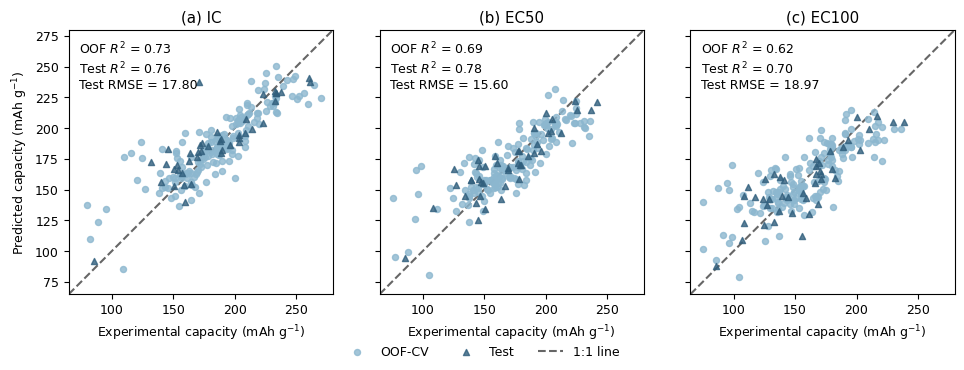

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5), sharex=True, sharey=True)
for panel, stage, ax in zip("abc", stages, axes):
    saved = bundle["predictions"]["GBR", stage]
    stats = metrics.set_index(["Model", "Stage"]).loc["GBR", stage]
    for name, marker, color, label in [
        ("CV_validation", "o", "#8CB7CF", "OOF-CV"),
        ("Independent_test", "^", "#315F7D", "Test"),
    ]:
        points = saved[saved.dataset.eq(name)]
        ax.scatter(points.actual, points.predicted, marker=marker, c=color, s=19, alpha=.8, label=label)
    ax.plot([65, 280], [65, 280], "--", color="0.4", label="1:1 line", zorder=0)
    ax.set(xlim=(65, 280), ylim=(65, 280), aspect="equal", title=f"({panel}) {stage}",
           xlabel=f"Experimental capacity ({capacity})")
    ax.text(.04, .96, f"OOF $R^2$ = {stats['Pooled OOF R²']:.2f}\n"
            f"Test $R^2$ = {stats['Test R²']:.2f}\nTest RMSE = {stats['Test RMSE']:.2f}",
            transform=ax.transAxes, va="top")
axes[0].set_ylabel(f"Predicted capacity ({capacity})")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False)
fig.tight_layout(rect=(0, .09, 1, 1))
plt.show()

## Figure 3 · SHAP beeswarms

Each panel ranks features by its own mean absolute SHAP. The horizontal coordinates are the original signed test-set SHAP values.

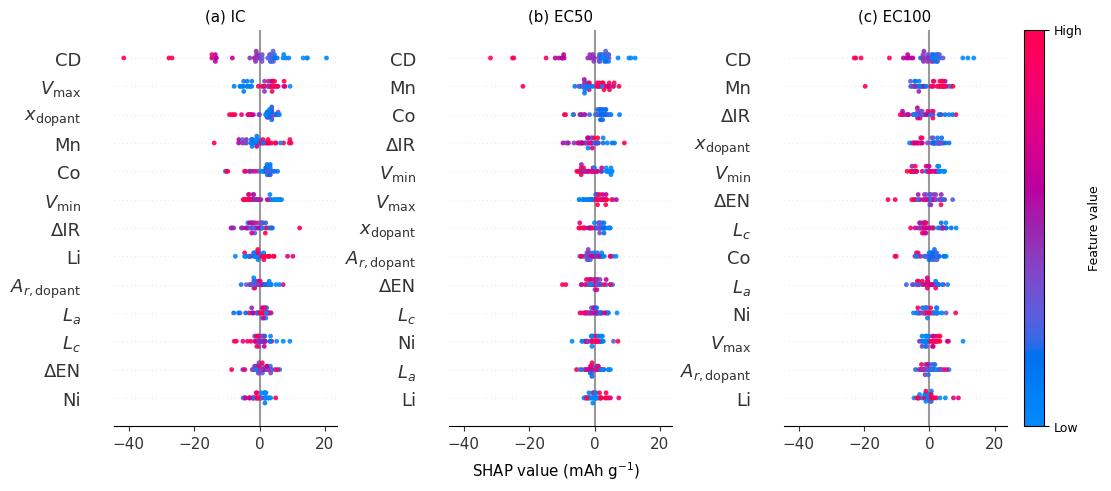

In [4]:
X_test, signed, _ = bundle["signed_shap"]
np.testing.assert_array_equal(X_test, X.loc[X_test.index, X_test.columns])
names = [labels.get(name, name) for name in X_test.columns]
all_shap = np.concatenate(list(signed.values()))
margin = .05 * np.ptp(all_shap)
fig, axes = plt.subplots(1, 3, figsize=(11, 4.8), layout="constrained")
for panel, stage, ax in zip("abc", stages, axes):
    explanation = shap.Explanation(values=signed[stage], data=X_test.to_numpy(), feature_names=names)
    shap.plots.beeswarm(explanation, ax=ax, plot_size=None, max_display=len(names),
                        color_bar=False, show=False, s=12, alpha=.9)
    ax.set(xlim=(all_shap.min()-margin, all_shap.max()+margin), title=f"({panel}) {stage}", xlabel="")
fig.supxlabel(f"SHAP value ({capacity})")
bar = fig.colorbar(plt.cm.ScalarMappable(cmap=shap.plots.colors.red_blue), ax=axes,
                   fraction=.025, pad=.02, ticks=[0, 1], label="Feature value")
bar.ax.set_yticklabels(["Low", "High"])
plt.show()

## Figure 4 · Normalized SHAP contribution

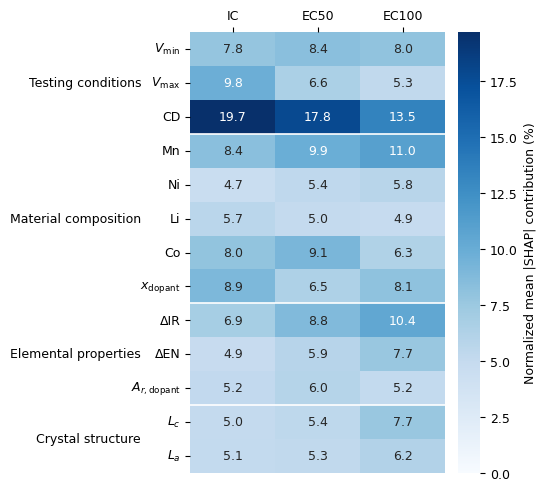

In [5]:
groups = {
    "Testing conditions": ["V_min", "V_max", "CD"],
    "Material composition": ["Mn", "Ni", "Li", "Co", "dopant_M"],
    "Elemental properties": ["△IR", "△EN", "Mr_dopant"],
    "Crystal structure": ["L_c", "L_a"],
}
importance = pd.DataFrame({stage: np.abs(signed[stage]).mean(axis=0) for stage in stages},
                          index=X_test.columns)
shares = 100 * importance / importance.sum()
ordered = [name for members in groups.values() for name in members]
fig, ax = plt.subplots(figsize=(5.3, 4.8), layout="constrained")
sns.heatmap(shares.loc[ordered].rename(index=labels), annot=True, fmt=".1f", cmap="Blues", vmin=0,
            cbar_kws={"label": "Normalized mean |SHAP| contribution (%)"}, ax=ax)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
start = 0
for group, members in groups.items():
    ax.text(-.58, start + len(members)/2, group, ha="right", va="center")
    start += len(members)
    if start < len(ordered):
        ax.axhline(start, color="white", lw=1.2)
ax.xaxis.tick_top()
plt.show()

## Figure 5 · Stage differences and SHAP dependence

Error bars use the archived pointwise 95% intervals from 5,000 paired resamples of the 43 test rows with fixed models.

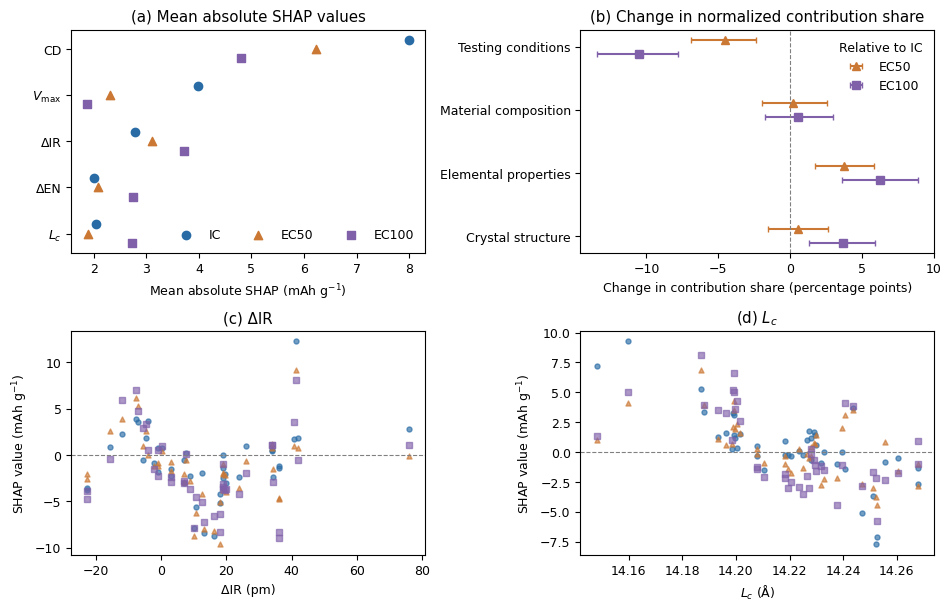

In [6]:
key_features = ["CD", "V_max", "△IR", "△EN", "L_c"]
class_share = pd.DataFrame({group: shares.loc[members].sum() for group, members in groups.items()}).T
fig, axs = plt.subplots(2, 2, figsize=(9.4, 6), layout="constrained")
a, b, c, d = axs.flat
y = np.arange(len(key_features))
for j, stage in enumerate(stages):
    color, marker = style[stage]
    a.scatter(importance.loc[key_features, stage], y + (j-1)*.2,
              c=color, marker=marker, label=stage)
    for ax, name in [(c, "△IR"), (d, "L_c")]:
        ax.scatter(X_test[name], signed[stage][:, X_test.columns.get_loc(name)],
                   c=color, marker=marker, s=13, alpha=.65)
a.set(yticks=y, yticklabels=[labels.get(name, name) for name in key_features],
      xlabel=f"Mean absolute SHAP ({capacity})", title="(a) Mean absolute SHAP values")
a.invert_yaxis()
a.legend(frameon=False, ncol=3)

# Archived percentile endpoints, grouped by stage contrast and descriptor class.
bounds = np.array([(-6.868363261415414, -2.3878519946024075), (-1.987347000069075, 2.593141579046218), (1.743942248863882, 5.86057983957205), (-1.52172722023689, 2.603964620378593), (-13.48040574788472, -7.807480171102528), (-1.7536992097191753, 2.9544671064368853), (3.623704255222903, 8.923458621807079), (1.3283186085228256, 5.908877690219292)]).reshape(2, 4, 2)

y = np.arange(len(groups))
for j, stage in enumerate(stages[1:]):
    center = (class_share[stage] - class_share.IC).to_numpy()
    low, high = bounds[j].T
    color, marker = style[stage]
    b.errorbar(center, y + (j-.5)*.22, xerr=[center-low, high-center], fmt=marker,
               color=color, capsize=2, label=stage)
b.axvline(0, color="0.5", ls="--", lw=.8)
b.set(yticks=y, yticklabels=list(groups), xlabel="Change in contribution share (percentage points)",
      title="(b) Change in normalized contribution share")
b.invert_yaxis()
b.legend(title="Relative to IC", frameon=False)
for ax, panel, name, unit in [(c, "c", "△IR", "pm"), (d, "d", "L_c", "Å")]:
    ax.axhline(0, color="0.5", ls="--", lw=.8)
    ax.set(xlabel=f"{labels[name]} ({unit})", ylabel=f"SHAP value ({capacity})",
           title=f"({panel}) {labels[name]}")
plt.show()

## Figure S1 · Dataset distributions

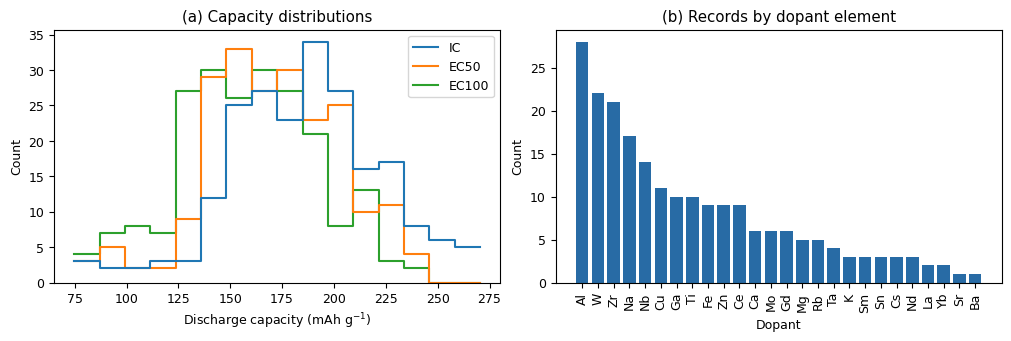

In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")
sns.histplot(data[list(stages)], bins=16, element="step", fill=False, ax=a)
a.set(title="(a) Capacity distributions", xlabel=f"Discharge capacity ({capacity})")
counts = data.Dopant_element.value_counts()
b.bar(counts.index, counts.values, color="#286BA5")
b.tick_params(axis="x", labelrotation=90)
b.set(title="(b) Records by dopant element", xlabel="Dopant", ylabel="Count")
plt.show()

## Figure S2 · Pearson correlation

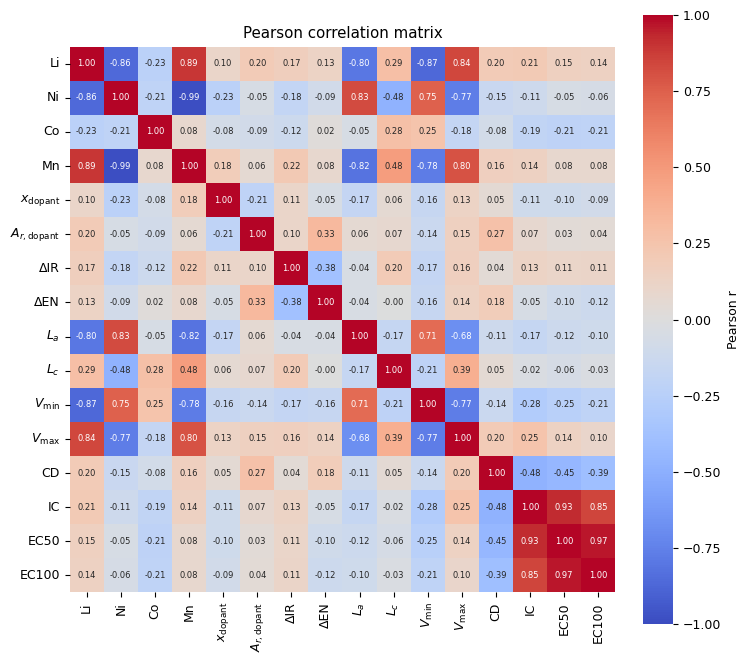

In [8]:
correlation = X.join(data[list(stages)]).rename(columns=labels).corr()
fig, ax = plt.subplots(figsize=(7.4, 6.6), layout="constrained")
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, annot_kws={"size": 6}, cbar_kws={"label": "Pearson r"}, ax=ax)
ax.set_title("Pearson correlation matrix")
plt.show()